# Stable Diffusion 3.5: generating images from text

[Stable Diffusion 3.5 Medium](https://huggingface.co/stabilityai/stable-diffusion-3.5-medium) (Stability AI,
October 2024) is an open-weights **text-to-image** model: given a prompt, it turns random noise into an image in a few
dozen denoising steps. It is a *latent diffusion* model — a VAE compresses images into a small latent space, text
encoders read the prompt, and a 2.2 B-parameter Transformer (the MMDiT) removes noise step by step. The
StableDiffusionArchitecture notebook takes it apart; this one is about **using** it with Hugging Face `diffusers`:
the generation parameters, what the model does well and badly, and editing existing images.

**Setup.** Needs a GPU (a T4 on `ml.g4dn` is enough: about a minute per 512 × 512 image). The weights (6.7 GB) are
mirrored with their license in the course bucket, because the Hugging Face repository is gated; they are downloaded
once to `sd35_model/` next to this notebook (shared with the architecture notebook). Delete that folder when you are
done if your space runs out of disk. The model's optional third text encoder, T5-XXL (9.5 GB), is left out, which
costs some prompt understanding (section 7).

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import s3fs
import torch
from diffusers import StableDiffusion3Img2ImgPipeline, StableDiffusion3InpaintPipeline, StableDiffusion3Pipeline
from diffusers.utils import logging as diffusers_logging
from PIL import Image, ImageDraw
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32  # the T4 has no fast bfloat16 (the release precision)

MODEL_S3 = "danylo-ucla/models/stabilityai/stable-diffusion-3.5-medium"
MODEL_DIR = Path("sd35_model")
if not (MODEL_DIR / "transformer" / "diffusion_pytorch_model.safetensors").exists():
    s3fs.S3FileSystem().get(f"{MODEL_S3}/", str(MODEL_DIR), recursive=True)


def show(images, titles=None, columns=None, size=4.0, suptitle=None):
    columns = columns or len(images)
    rows = -(-len(images) // columns)
    widths = [image.width / image.height for image in images[:columns]]
    fig, axes = plt.subplots(rows, columns, figsize=(size * sum(widths), size * rows + 0.3), squeeze=False,
                             layout="constrained", width_ratios=widths)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles or [None] * len(images)):
        ax.imshow(image)
        if title:
            ax.set_title(title, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.show()


def seeded(seed):
    return torch.Generator(device).manual_seed(seed)

## 1. Text to image

`StableDiffusion3Pipeline` bundles the VAE, the two CLIP text encoders, the MMDiT and the sampler. We tell it to skip
the T5 encoder (`text_encoder_3=None`) and load the half-precision weights:

In [2]:
pipe = StableDiffusion3Pipeline.from_pretrained(MODEL_DIR, text_encoder_3=None, tokenizer_3=None, dtype=dtype,
                                                variant="fp16").to(device)
pipe.set_progress_bar_config(disable=True)
print({name: f"{sum(p.numel() for p in c.parameters()) / 1e9:.2f} B" for name, c in pipe.components.items()
       if isinstance(c, torch.nn.Module)})

{'vae': '0.08 B', 'text_encoder': '0.12 B', 'text_encoder_2': '0.69 B', 'transformer': '2.24 B'}


One call generates an image. The main parameters:

- `prompt`: what to draw;
- `height`, `width`: the size in pixels, a multiple of 16. The model was trained up to about 1 megapixel
  (1024 × 1024); 512 × 512 is 4 times faster and still good;
- `num_inference_steps`: how many denoising steps (default 40; 28 is the usual choice for SD 3.5 Medium);
- `guidance_scale`: how strongly to follow the prompt (default 7; 4–5 for this model);
- `generator`: the source of the random starting noise. A seeded generator makes the image reproducible.

2.1 s for 28 steps, peak GPU memory 7.9 GB


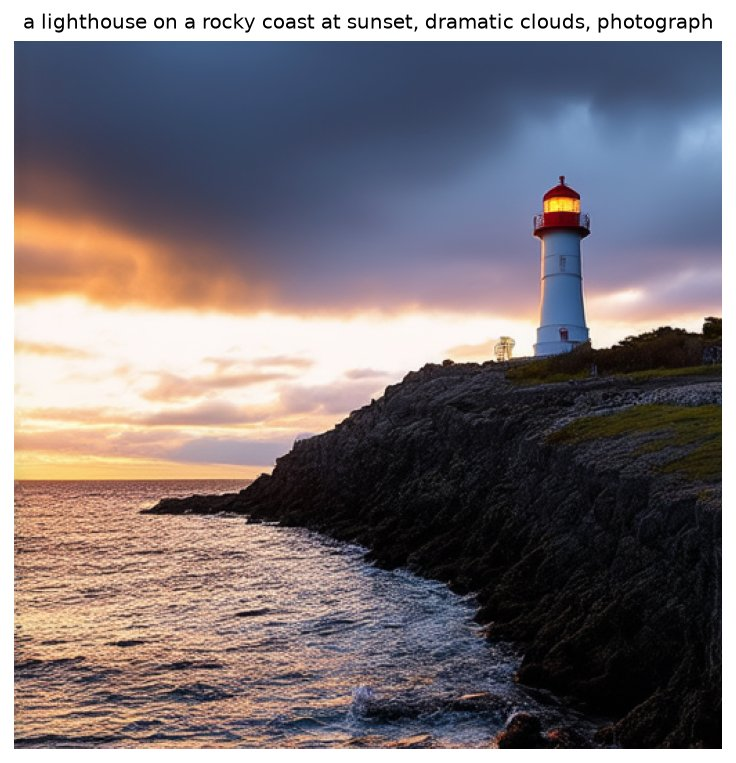

In [3]:
def generate(prompt, seed=0, size=(512, 512), steps=28, guidance=5.0, **kwargs):
    return pipe(prompt, width=size[0], height=size[1], num_inference_steps=steps, guidance_scale=guidance,
                generator=seeded(seed), **kwargs).images


if device == "cuda":
    torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
image = generate("a lighthouse on a rocky coast at sunset, dramatic clouds, photograph")[0]
seconds = time.perf_counter() - start
if device == "cuda":
    print(f"{seconds:.1f} s for 28 steps, peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
show([image], ["a lighthouse on a rocky coast at sunset, dramatic clouds, photograph"], size=5)

## 2. Seeds and batches

The prompt doesn't determine the image: the starting noise does the rest. Different seeds give different
compositions; the same seed always gives the same image (on the same GPU type and library versions).
`num_images_per_prompt` generates several images in one batch, each from its own noise:

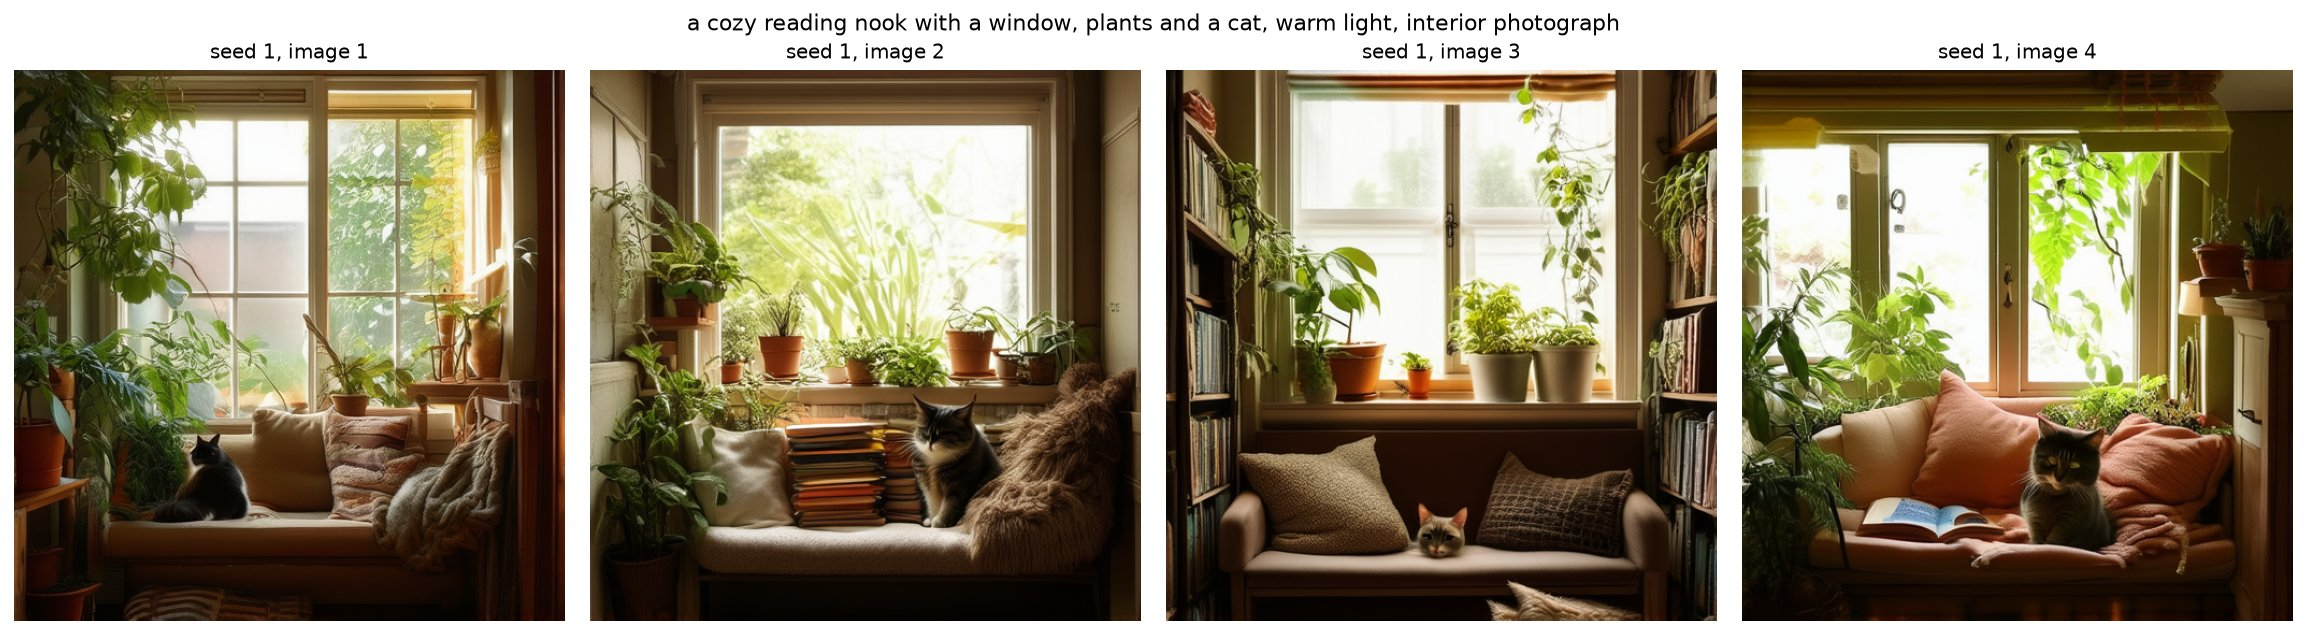

In [4]:
PROMPT = "a cozy reading nook with a window, plants and a cat, warm light, interior photograph"
batch = generate(PROMPT, seed=1, num_images_per_prompt=4)
show(batch, [f"seed 1, image {i + 1}" for i in range(4)], suptitle=PROMPT)

## 3. Number of steps

Each step is one pass of the MMDiT (two with guidance), so the time grows linearly with the steps. Few steps give
blurry, unfinished images; beyond about 30 the image hardly changes. Models distilled for speed (SD 3.5 Large Turbo,
SD-Turbo) need only 1–4 steps.

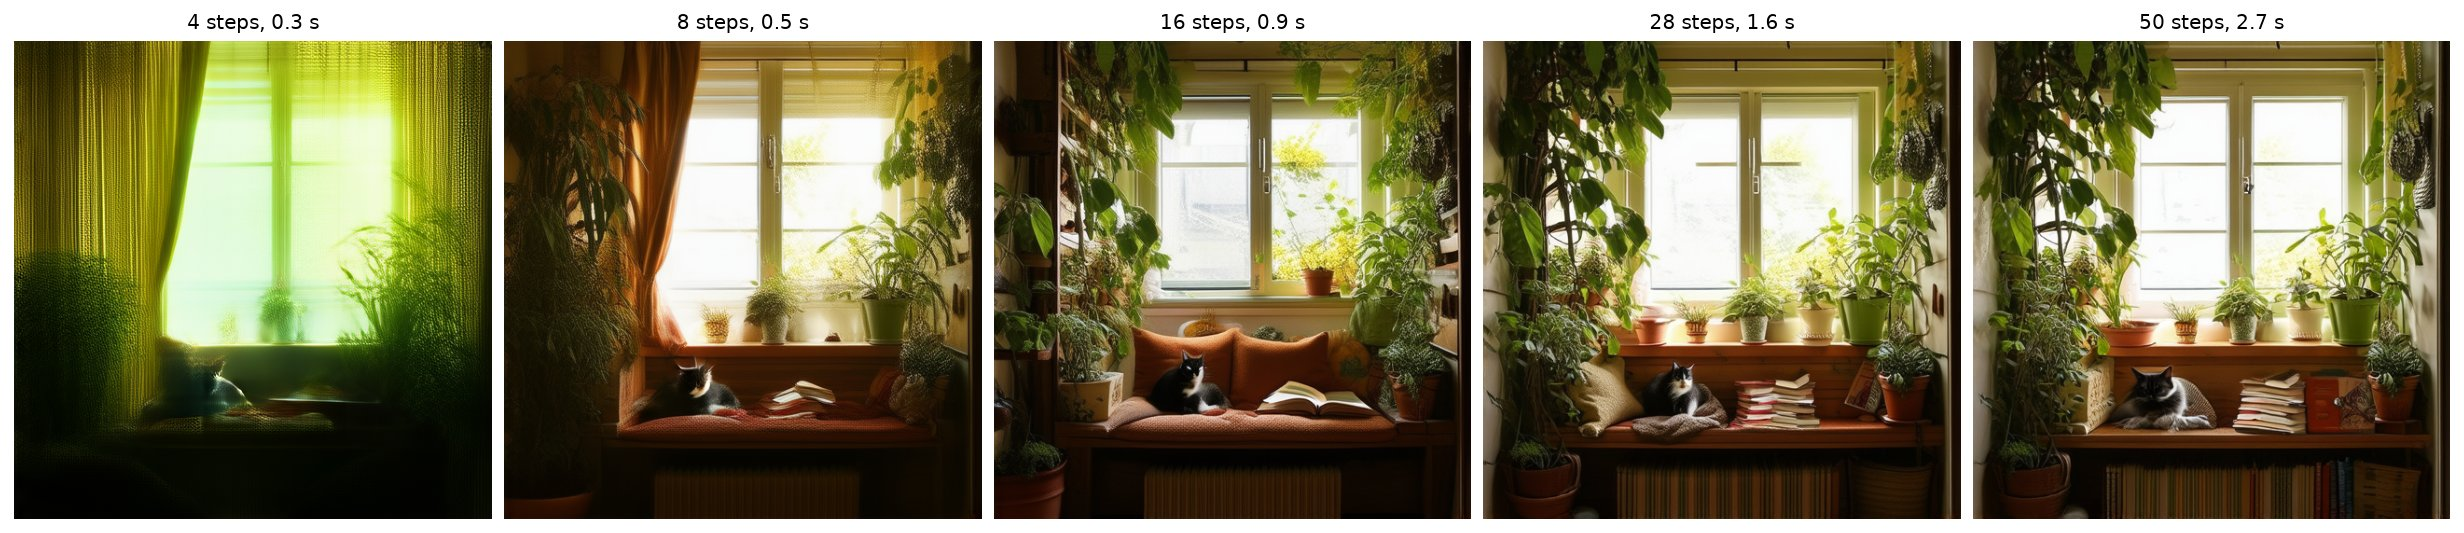

In [5]:
steps, images, seconds = [4, 8, 16, 28, 50], [], []
for n in steps:
    start = time.perf_counter()
    images.append(generate(PROMPT, seed=2, steps=n)[0])
    seconds.append(time.perf_counter() - start)
show(images, [f"{n} steps, {s:.1f} s" for n, s in zip(steps, seconds)], size=3.4)

## 4. Guidance and negative prompts

**Classifier-free guidance** runs the model twice per step, with the prompt and with a *negative* prompt (by default
the empty one), and pushes the image away from the negative prediction by the factor `guidance_scale`. Low values
give natural but loosely matching images; high values follow the prompt more literally, with saturated colors and
harsh contrast.

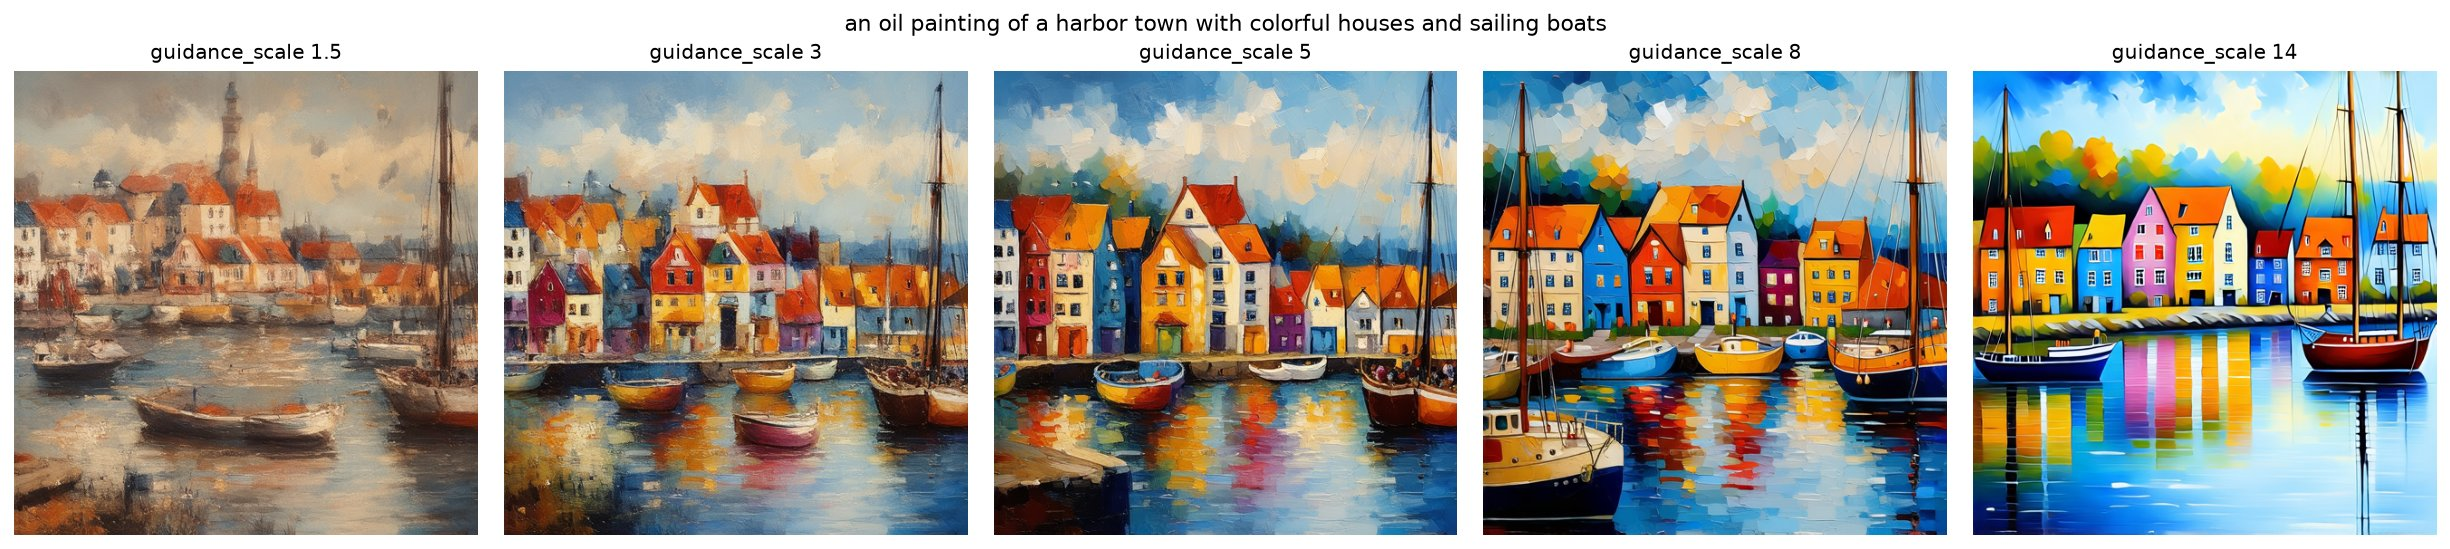

In [6]:
PAINTING = "an oil painting of a harbor town with colorful houses and sailing boats"
scales = [1.5, 3.0, 5.0, 8.0, 14.0]
show([generate(PAINTING, seed=3, guidance=w)[0] for w in scales], [f"guidance_scale {w:g}" for w in scales], size=3.4,
     suptitle=PAINTING)

The **negative prompt** replaces the empty prompt, so the image is pushed away from what it describes — a way to
remove things the prompt alone doesn't exclude:

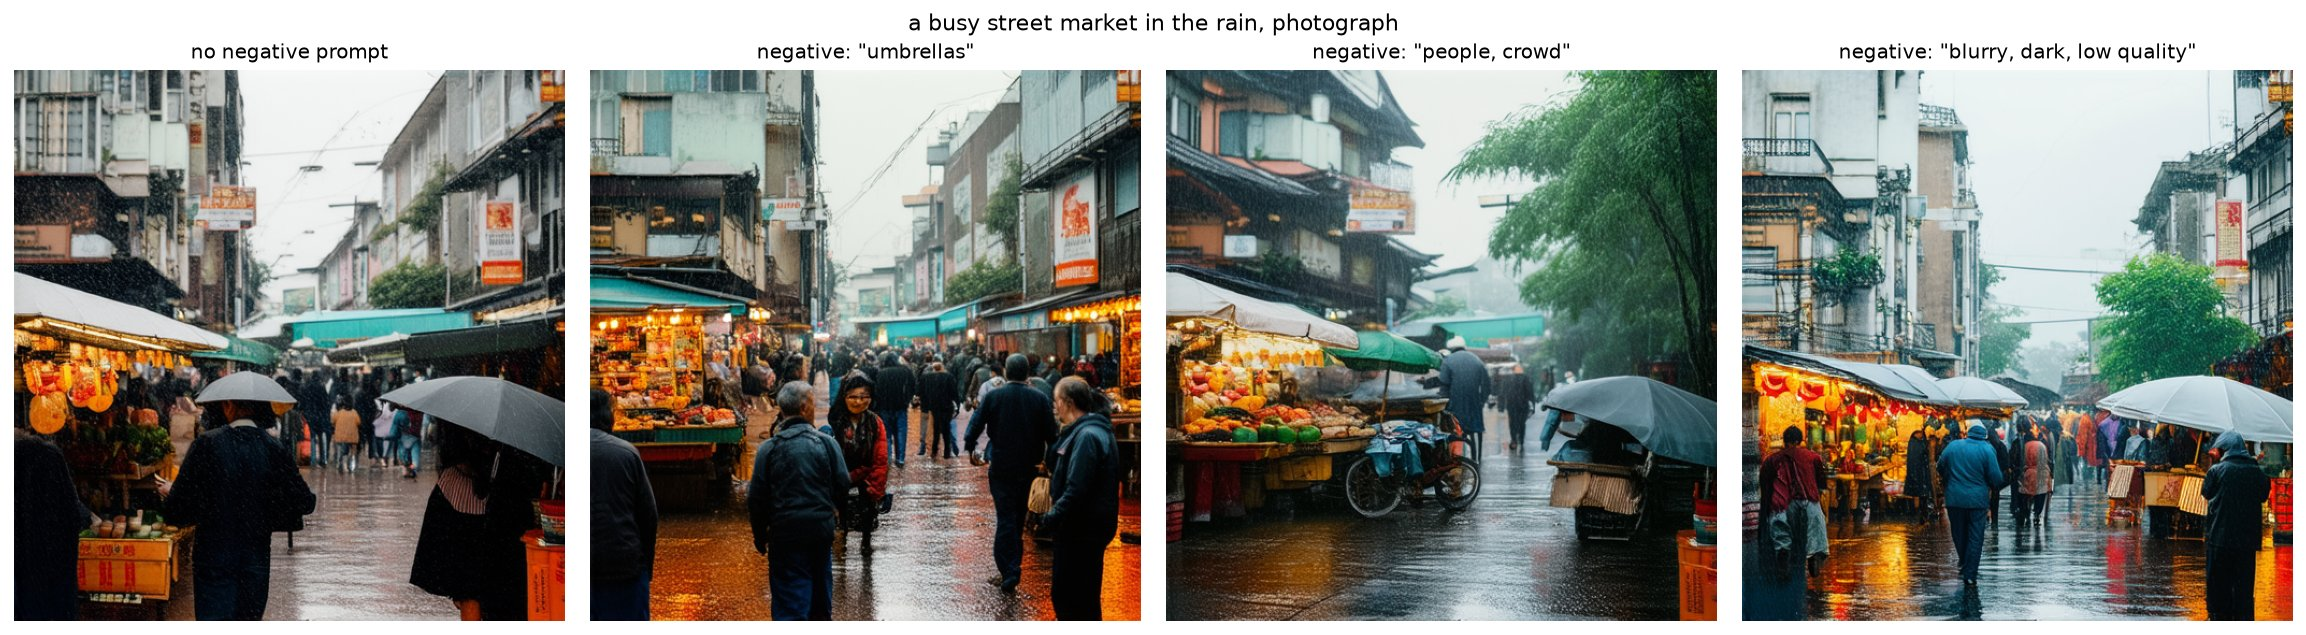

In [7]:
STREET = "a busy street market in the rain, photograph"
negatives = [None, "umbrellas", "people, crowd", "blurry, dark, low quality"]
show([generate(STREET, seed=4, negative_prompt=n)[0] for n in negatives],
     ["no negative prompt" if n is None else f'negative: "{n}"' for n in negatives], suptitle=STREET)

## 5. Prompts: subject, style, composition

The prompt describes the subject *and* the look of the image. The same subject and seed in four styles:

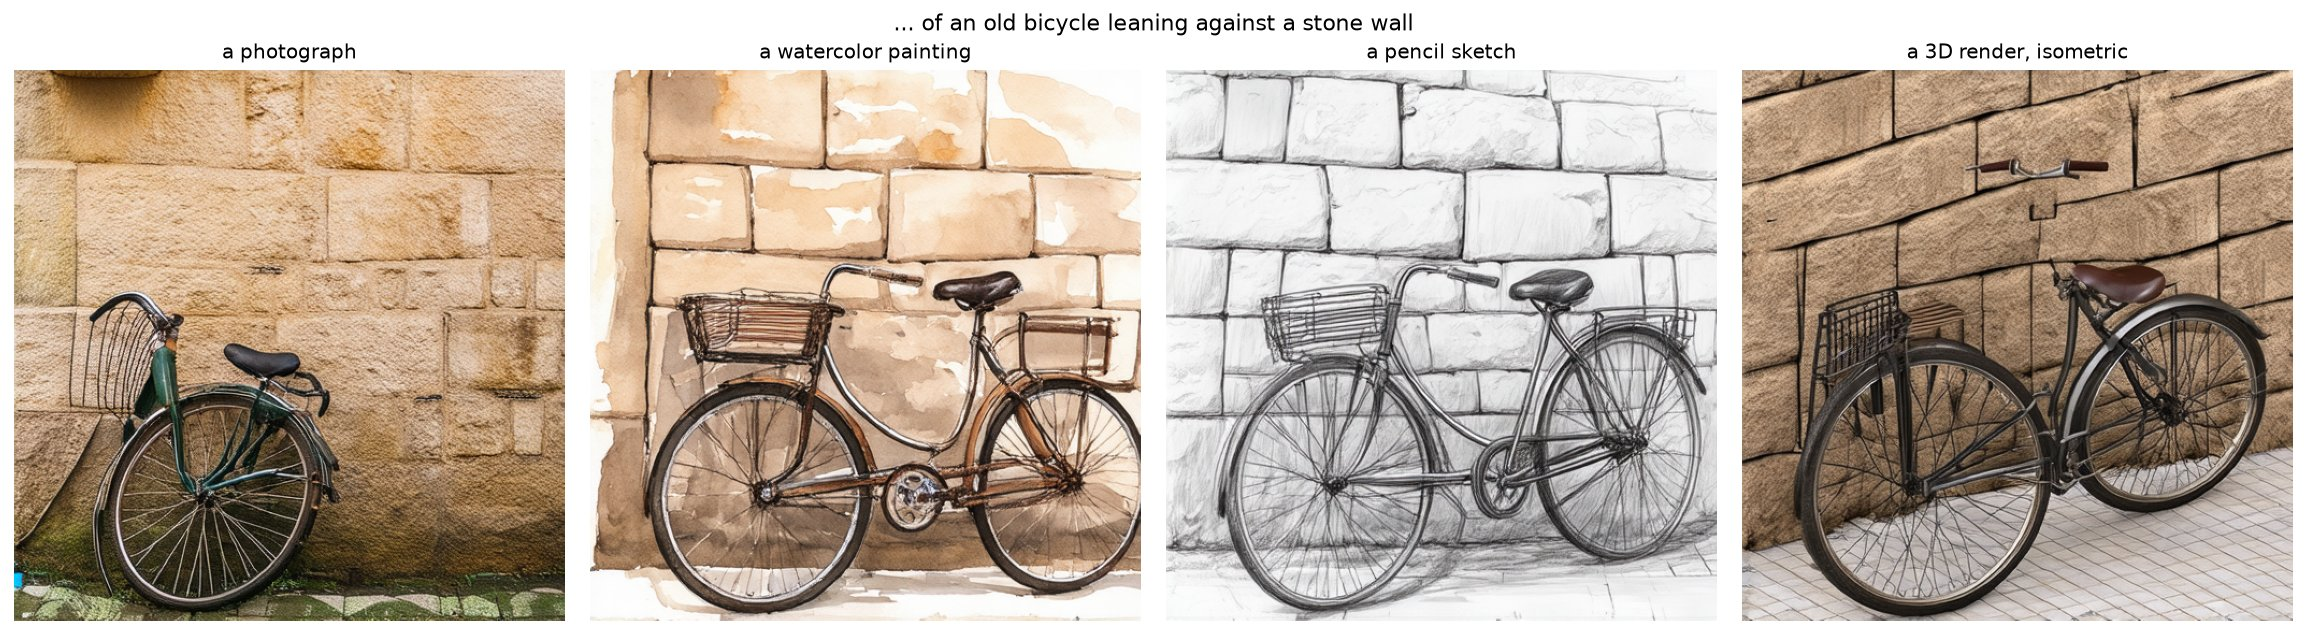

In [8]:
styles = ["a photograph", "a watercolor painting", "a pencil sketch", "a 3D render, isometric"]
show([generate(f"{style} of an old bicycle leaning against a stone wall", seed=5)[0] for style in styles],
     styles, suptitle="... of an old bicycle leaning against a stone wall")

## 6. Sizes and aspect ratios

The image size is free (multiples of 16). The model was trained at about 1 megapixel in many aspect ratios, so wide
and tall images are composed for their format rather than cropped. Time and memory grow with the number of pixels —
faster than linearly, because the attention compares every pair of the $(\text{height} / 16) \times
(\text{width} / 16)$ image patches.

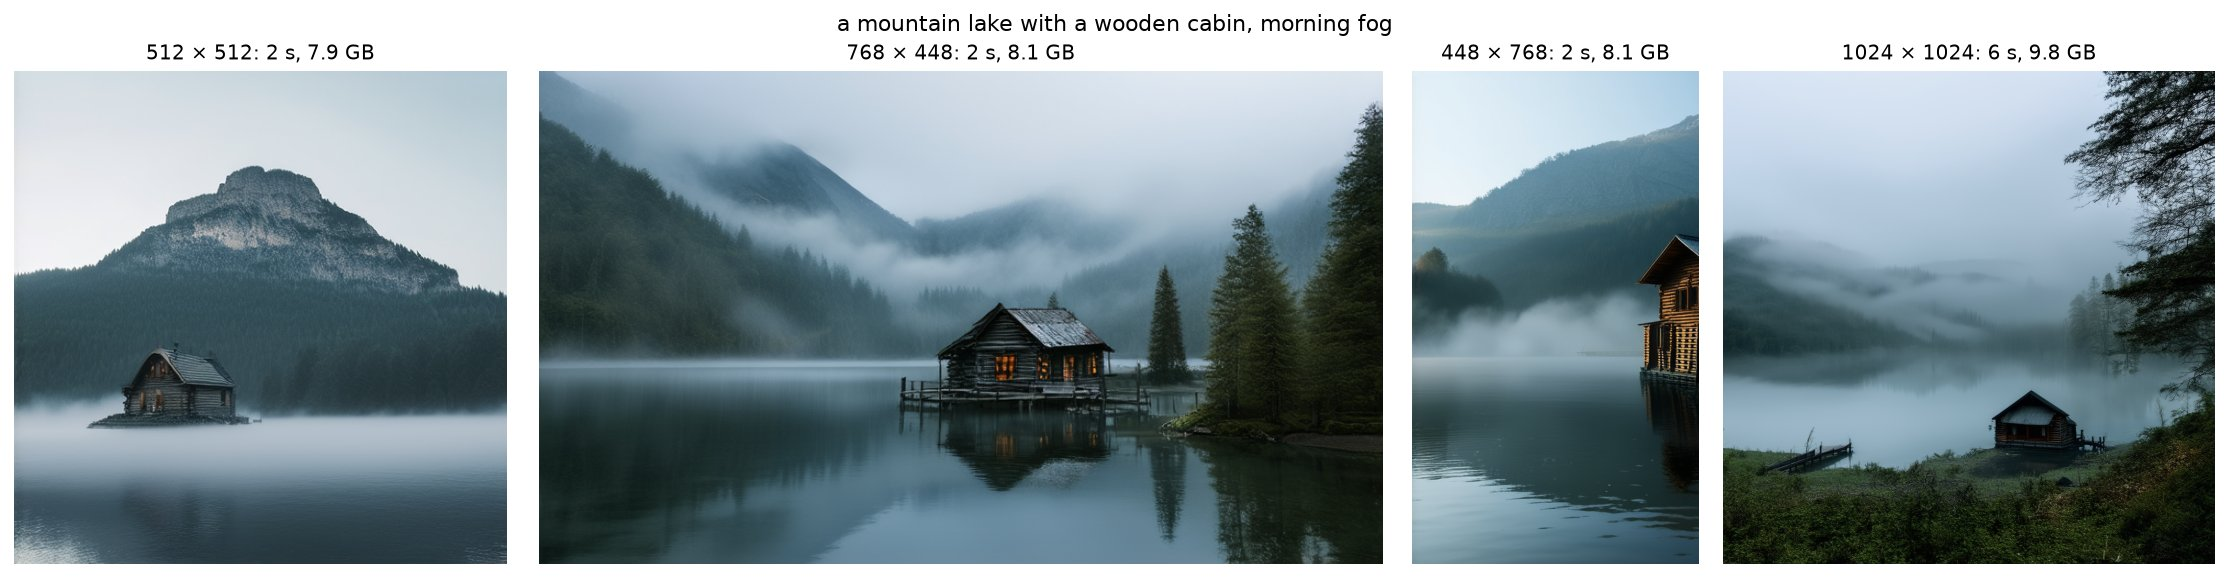

In [9]:
LANDSCAPE = "a mountain lake with a wooden cabin, morning fog"
sizes = [(512, 512), (768, 448), (448, 768), (1024, 1024)]
images, titles = [], []
for size in sizes:
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    images.append(generate(LANDSCAPE, seed=6, size=size)[0])
    memory = f", {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == "cuda" else ""
    titles.append(f"{size[0]} × {size[1]}: {time.perf_counter() - start:.0f} s{memory}")
show(images, titles, size=3.6, suptitle=LANDSCAPE)

## 7. Limits

**Long prompts.** The CLIP encoders read at most **77 tokens**; the rest of a longer prompt is cut off without an
error. (T5, which we left out, would read 256 tokens.) Put the important parts first.

In [10]:
long_prompt = ("a detailed fantasy illustration of a floating island with waterfalls pouring into the clouds, a small "
               "village of round stone houses with red roofs, a winding path lined with lanterns, giant mushrooms, a "
               "flock of white birds circling the island, a dragon sleeping on the highest cliff, two moons in a "
               "violet sky, a hot air balloon tied to a wooden dock, a lighthouse with a green light at the edge of the "
               "island, and a red fox sitting on a bench in the foreground")
tokens = pipe.tokenizer(long_prompt).input_ids
print(f"{len(tokens)} tokens; the model reads: ...{pipe.tokenizer.decode(tokens[60:76])}")
print("cut off:", pipe.tokenizer.decode(tokens[76:-1]))

96 tokens; the model reads: ..., a hot air balloon tied to a wooden dock , a lighthouse with a green
cut off: light at the edge of the island , and a red fox sitting on a bench in the foreground


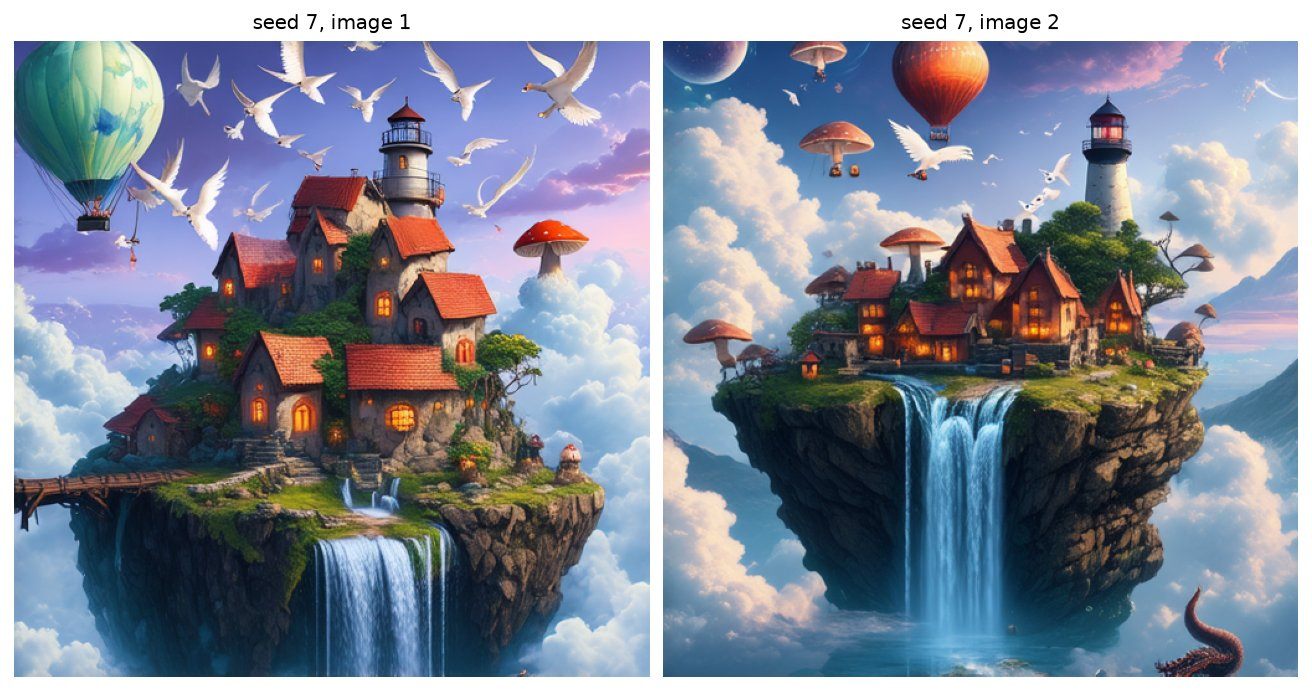

In [11]:
show(generate(long_prompt, seed=7, num_images_per_prompt=2), ["seed 7, image 1", "seed 7, image 2"], size=4.5)

Both images have the island, the waterfalls, the village, the birds, the mushrooms, the balloon and the lighthouse.
The lighthouse's green light, the fox and the bench came after the cut and are missing. Even parts the model did
read get lost in a long list: the sleeping dragon is at most a tail, the two moons at most one planet.

**Text, counting, and spatial relations** are typical weaknesses of diffusion models. SD3 improved on all three,
mostly with T5's help:

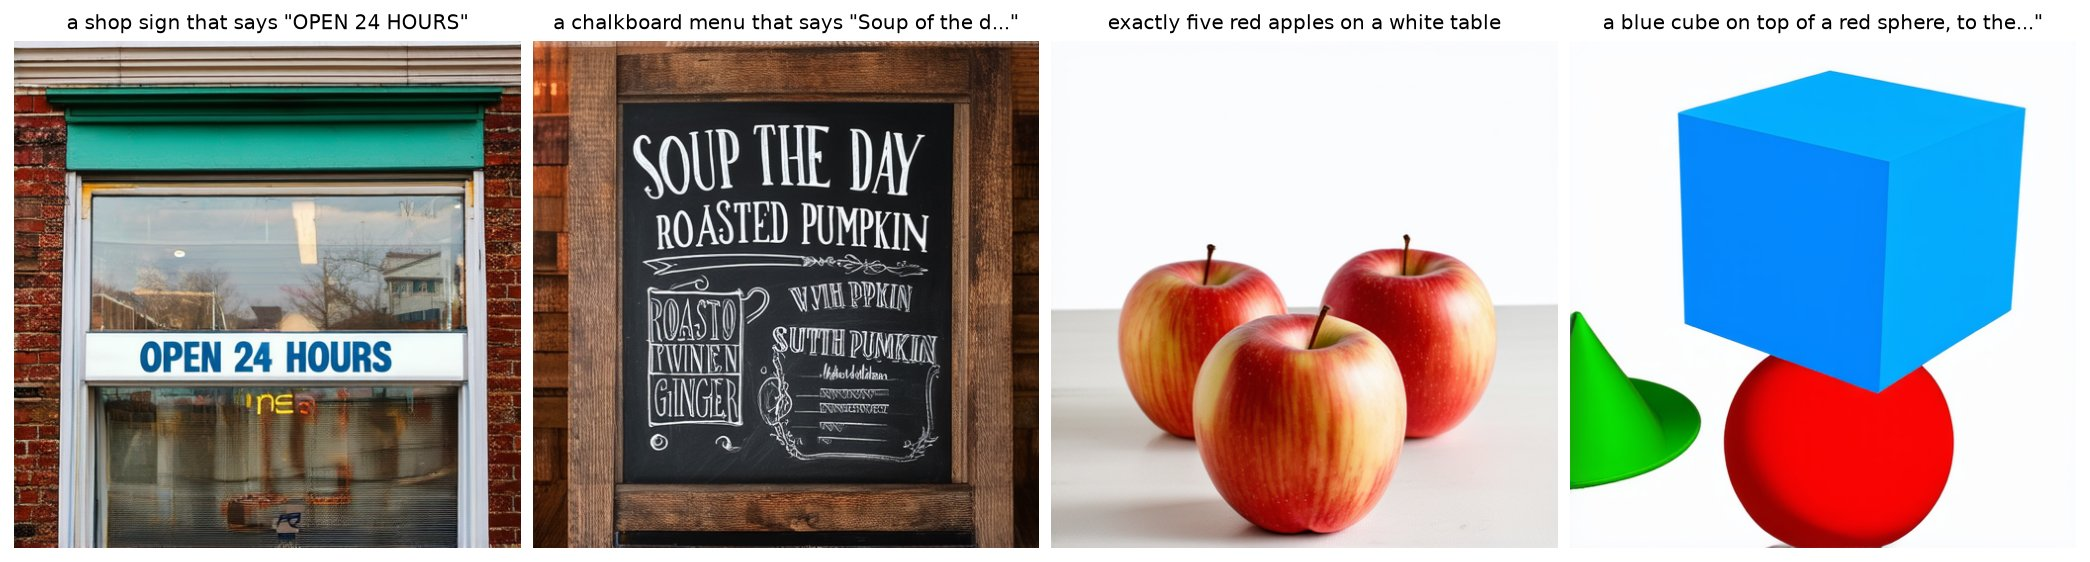

In [12]:
hard = ['a shop sign that says "OPEN 24 HOURS"',
        'a chalkboard menu that says "Soup of the day: roasted pumpkin with ginger"',
        "exactly five red apples on a white table", "a blue cube on top of a red sphere, to the left of a green cone"]
show([generate(p, seed=8)[0] for p in hard], [p if len(p) < 45 else p[:42] + '..."' for p in hard], size=3.6)

The short sign is spelled correctly, but the longer menu falls apart into misspelled words ("SOUP THE DAY",
"WVIH PPKIN"): the model has learned the look of lettering and the shape of short common words, not spelling. It
draws three apples instead of five — numbers beyond two or three are rarely right. The spatial relation is correct
here; such prompts succeed more often than with SD 1.x, but not always.

## 8. Image to image

`StableDiffusion3Img2ImgPipeline` starts from an existing image instead of pure noise: it encodes the image with the
VAE, adds noise up to a level set by `strength` (0: none, the image is returned unchanged; 1: pure noise, the image is
ignored), and runs only the remaining denoising steps with the new prompt. Low strength keeps the composition and
changes the surface; high strength keeps only the rough layout and colors. `from_pipe` reuses the loaded models, so
this costs no extra memory — but pass `dtype`: by default it converts the shared models to float32, which makes every
pipeline that uses them (including `pipe`) several times slower.

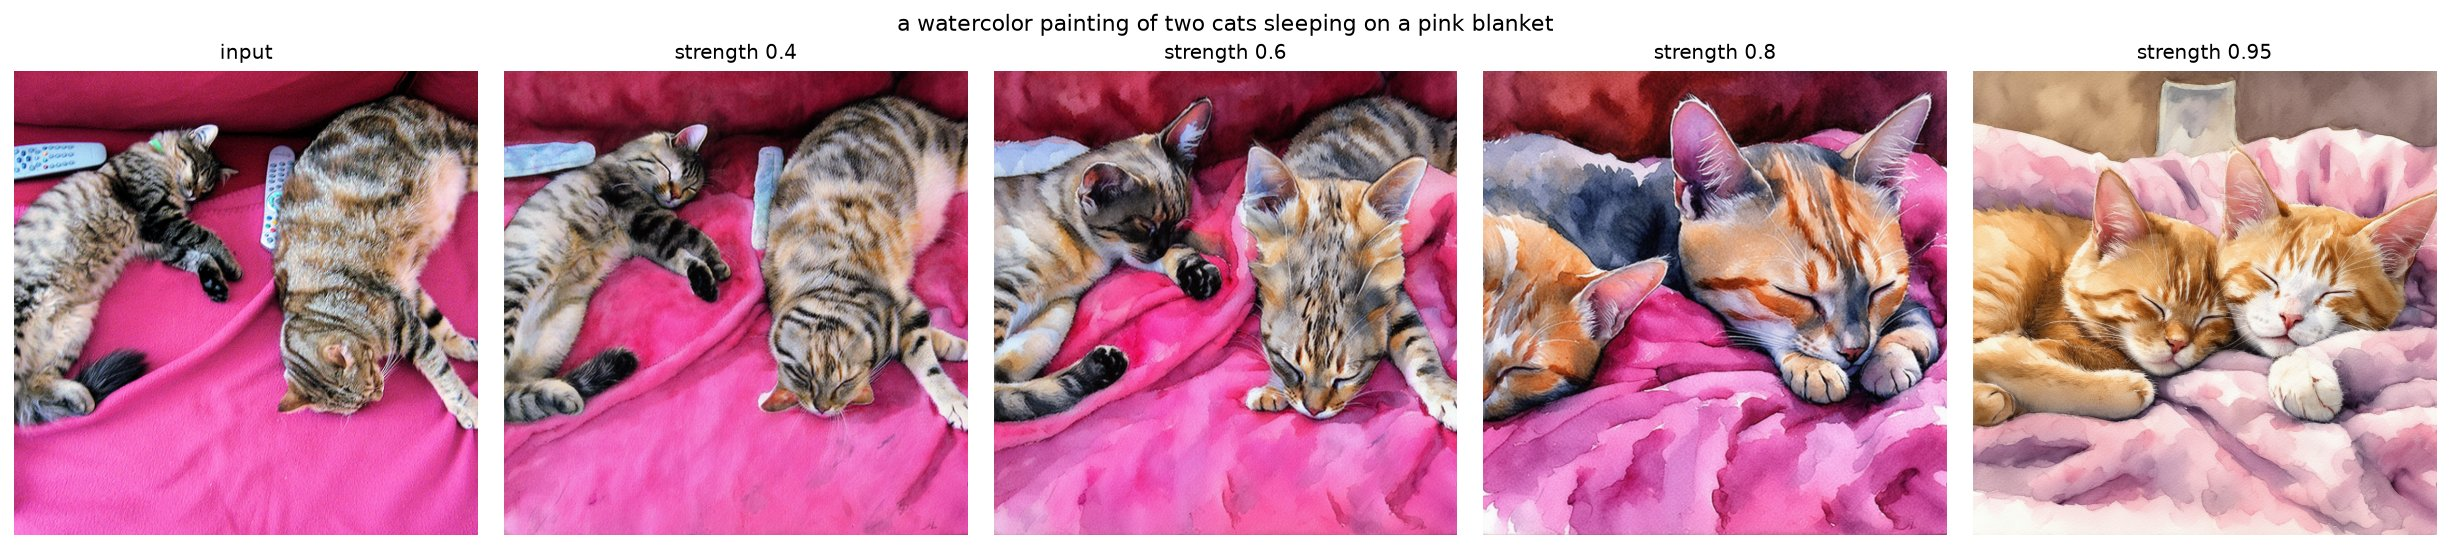

In [13]:
def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


cats = load_coco(39769).resize((683, 512)).crop((85, 0, 597, 512))   # the cats from the DETR notebook, 512 × 512
img2img = StableDiffusion3Img2ImgPipeline.from_pipe(pipe, dtype=dtype)  # without dtype, from_pipe casts to float32
img2img.set_progress_bar_config(disable=True)
WATERCOLOR = "a watercolor painting of two cats sleeping on a pink blanket"
strengths = [0.4, 0.6, 0.8, 0.95]
images = [img2img(WATERCOLOR, image=cats, strength=s, num_inference_steps=28, guidance_scale=5.0,
                  generator=seeded(9)).images[0] for s in strengths]
show([cats] + images, ["input"] + [f"strength {s:g}" for s in strengths], size=3.4, suptitle=WATERCOLOR)

At 0.4 the photo only gets painted texture; at 0.6 the cats are redrawn but stay in place; at 0.8 the composition
loosens (the remotes are gone); at 0.95 only the pink color scheme and "two cats" remain.

## 9. Inpainting

`StableDiffusion3InpaintPipeline` regenerates only a masked region (white in the mask) and keeps the rest. At every
step the unmasked part of the latent is reset to the (noised) original, so the new content has to fit its
surroundings. Here we replace the cat on the right:

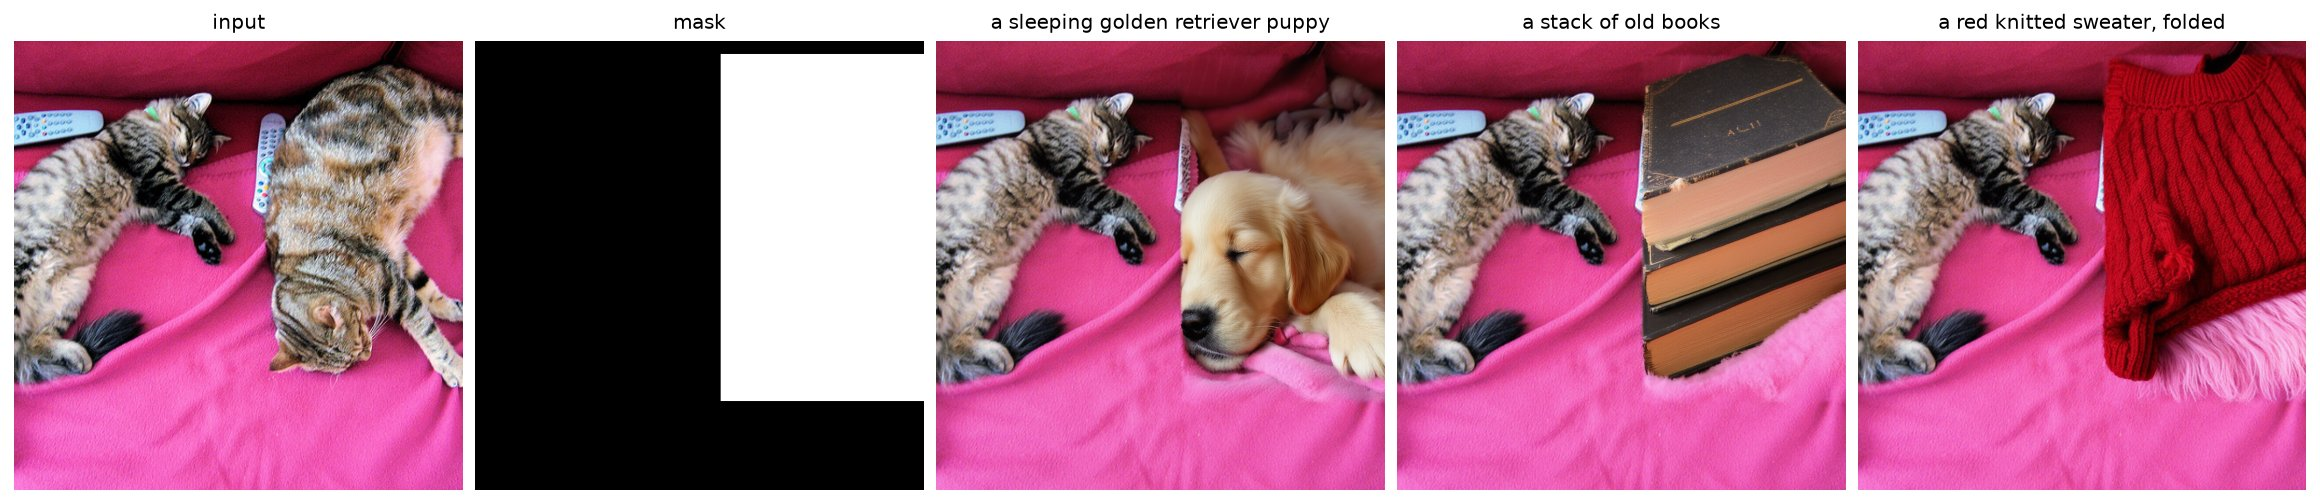

In [14]:
mask = Image.new("L", cats.size, 0)
ImageDraw.Draw(mask).rectangle((280, 15, 511, 410), fill=255)
inpaint = StableDiffusion3InpaintPipeline.from_pipe(pipe, dtype=dtype)
inpaint.set_progress_bar_config(disable=True)
replacements = ["a sleeping golden retriever puppy", "a stack of old books", "a red knitted sweater, folded"]
images = [inpaint(f"{r} on a pink blanket", image=cats, mask_image=mask, strength=0.95, num_inference_steps=28,
                  guidance_scale=5.0, generator=seeded(10)).images[0] for r in replacements]
show([cats, mask.convert("RGB")] + images, ["input", "mask"] + replacements, size=3.2)

The new objects match the lighting and perspective, and the left half is untouched. The mask edge stays visible where
the new content meets the old blanket (a seam of different texture): the model is not trained for inpainting, it only
has the noised surroundings as a guide. Dedicated inpainting models, a mask that follows the object's outline, or
`padding_mask_crop` (regenerate a crop around the mask at full resolution) give cleaner results.

## Summary

- `StableDiffusion3Pipeline(prompt, height, width, num_inference_steps, guidance_scale, generator)`: about 28 steps,
  guidance 4–5; the seed fixes the image, the batch dimension gives variations;
- `negative_prompt` steers away from content; the prompt's style words control the look; sizes are free up to about
  1 megapixel, and cost grows faster than the pixel count;
- CLIP reads at most 77 tokens; text, counts and spatial relations are unreliable (more so without T5);
- `StableDiffusion3Img2ImgPipeline` (`strength`) edits a whole image, `StableDiffusion3InpaintPipeline` a masked
  region — both reuse the loaded models with `from_pipe`;
- the outputs reflect the training data, including its biases.